# 02 · Tendencias temporales (Sprint 5 · Paso 2 - EDA)

Kernel: **Python (chicago-crimes)**.

**Objetivo:** leer los patrones de tiempo del crimen — mes a mes, día de la
semana, fin de semana vs entre semana, y el heatmap día×hora.

**Principio (plan §4 / AGENTS):** las agregaciones analíticas viven en las
**vistas del Sprint 4** (`vw_monthly_crimes`, `vw_month_over_month`,
`vw_day_hour`); este notebook las *consulta y grafica*, no re-agrega en
pandas. PostgreSQL transforma, Python presenta.

> **Nota de ventana de datos:** en dev la carga actual es ~1 mes
> (sept-2026). Las celdas de tendencia mensual y month-over-month salen con
> pocos puntos hasta que cargues una ventana mayor (Sprint 2 · Paso 3:
> bucle de 1 año). Los patrones de **día de la semana, fin de semana y
> hora** sí son significativos ya con 1 mes.


In [7]:
# Setup: imports, conexión a dev (5432) y helper de query
import sys
from decimal import Decimal
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

DB = dict(host="localhost", port=5432, user="postgres",
          password="postgres", dbname="chicago_crimes")
conn = psycopg2.connect(**DB)

def q(sql, params=None):
    """Query -> DataFrame (psycopg2 + pandas, sin SQLAlchemy).

    PG numeric (p.ej. round(...)) llega como Decimal; lo paso a float para
    que matplotlib pueda graficarlo (Decimal -> 'no numeric data to plot').
    """
    cur = conn.cursor()
    cur.execute(sql, params or ())
    cols = [d[0] for d in cur.description]
    out = pd.DataFrame(cur.fetchall(), columns=cols)
    cur.close()
    for c in out.columns:
        if out[c].map(lambda v: isinstance(v, Decimal)).any():
            out[c] = out[c].astype(float)
    return out

print("PostgreSQL", conn.info.server_version)


PostgreSQL 160015


## 1 · Ventana de datos real (qué hay cargado)


In [8]:
q("""
SELECT min(d.full_date)                                    AS primer_dia,
       max(d.full_date)                                    AS ultimo_dia,
       count(*)                                            AS crimenes,
       count(DISTINCT d.full_date)                         AS dias_distintos,
       count(DISTINCT date_trunc('month', d.full_date))    AS meses_distintos
FROM warehouse.fact_crime f
JOIN warehouse.dim_date d ON d.date_key = f.date_key
""").T.rename(columns={0: "valor"})


,valor
primer_dia,2026-09-01
ultimo_dia,2026-09-30
crimenes,19642
dias_distintos,30
meses_distintos,1


## 2 · Tendencia mensual — `vw_monthly_crimes`

Crímenes y arrestos por mes calendarario + tasa de arresto. Con 1 mes verás
una sola fila; se llena al ampliar la ventana.


In [9]:
monthly = q("SELECT * FROM warehouse.vw_monthly_crimes ORDER BY month_date")
display(monthly)

if len(monthly) > 1:
    fig, ax1 = plt.subplots(figsize=(11, 4))
    ax1.plot(monthly.month_date, monthly.crime_count, marker="o", label="crímenes")
    ax1.set_ylabel("crímenes")
    ax2 = ax1.twinx()
    ax2.plot(monthly.month_date, monthly.arrest_rate_pct, marker="s",
             color="tab:red", label="% arresto")
    ax2.set_ylabel("arrest_rate_pct (%)")
    ax1.set_title("Tendencia mensual (crímenes vs tasa de arresto)")
    fig.tight_layout()
else:
    print("Solo 1 mes cargado: sin línea que dibujar todavía "
          "(amplía la ventana en el Sprint 2 · Paso 3).")


,month_date,year,month,month_name,crime_count,arrest_count,arrest_rate_pct
0,2026-09-01,2026,9,September,19642,2850,14.5


Solo 1 mes cargado: sin línea que dibujar todavía (amplía la ventana en el Sprint 2 · Paso 3).


## 3 · Month-over-month — `vw_month_over_month`

Delta vs el mes anterior (LAG en SQL). El primer mes sale con prev/change
en NULL (no tiene con qué comparar).


In [10]:
q("SELECT * FROM warehouse.vw_month_over_month ORDER BY month_date")


,month_date,crime_count,prev_crime_count,change_abs,change_pct
0,2026-09-01,19642,None,None,None


## 4 · Día de la semana

ISO: lunes=1 … domingo=7 (viene de `dim_date`, calculado con CASE fijo sin
locale). Agrupado desde el `fact_crime` + `dim_date`.


,day_of_week,day_name,crimes
0,1,Monday,2574
1,2,Tuesday,3241
2,3,Wednesday,3178
3,4,Thursday,2534
4,5,Friday,2780
5,6,Saturday,2745
6,7,Sunday,2590


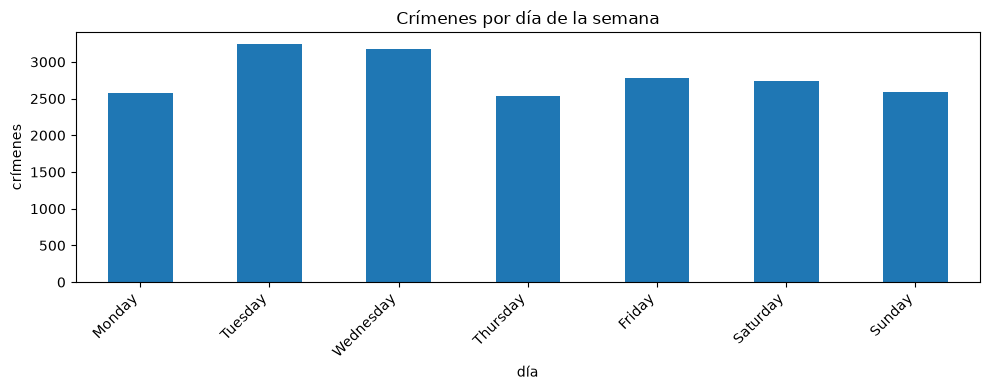

In [11]:
dow = q("""
SELECT d.day_of_week, d.day_name, count(*) AS crimes
FROM warehouse.fact_crime f
JOIN warehouse.dim_date d ON d.date_key = f.date_key
GROUP BY d.day_of_week, d.day_name
ORDER BY d.day_of_week
""")
display(dow)

ax = dow.plot.bar(x="day_name", y="crimes", figsize=(10, 4),
                  title="Crímenes por día de la semana", legend=False)
ax.set_xlabel("día"); ax.set_ylabel("crímenes"); ax.set_xticklabels(
    dow.day_name, rotation=45, ha="right")
plt.tight_layout()


## 5 · Fin de semana vs entre semana

`dim_date.is_weekend` (sáb/dom). Promedio por día para que sea comparable
aunque el mes tenga distinto nº de fines de semana.


,tipo,crimenes,dias,por_dia
0,entre semana,14307,22,650.3
1,fin de semana,5335,8,666.9


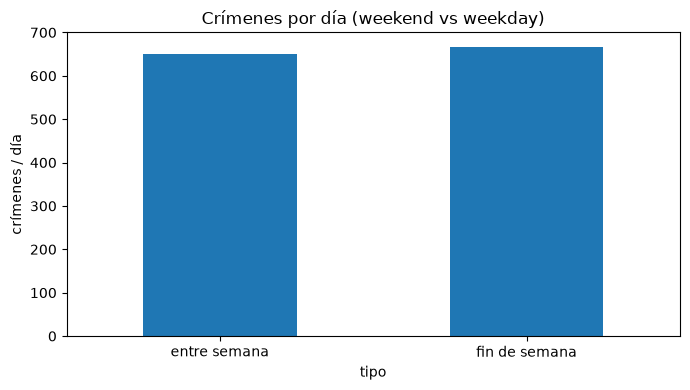

In [12]:
wk = q("""
SELECT d.is_weekend,
       count(*)                              AS crimenes,
       count(DISTINCT d.full_date)           AS dias,
       round(count(*)::numeric
             / count(DISTINCT d.full_date), 1) AS por_dia
FROM warehouse.fact_crime f
JOIN warehouse.dim_date d ON d.date_key = f.date_key
GROUP BY d.is_weekend
ORDER BY d.is_weekend
""")
wk["tipo"] = np.where(wk.is_weekend, "fin de semana", "entre semana")
display(wk[["tipo", "crimenes", "dias", "por_dia"]])

wk.sort_values("is_weekend").plot.bar(x="tipo", y="por_dia", figsize=(7, 4),
                                      title="Crímenes por día (weekend vs weekday)",
                                      legend=False)
plt.ylabel("crímenes / día"); plt.xticks(rotation=0); plt.tight_layout()


## 6 · Heatmap día × hora — `vw_day_hour`

Matriz 7 (días ISO) × 24 (horas). Es el input del heatmap del dashboard
(Sprint 7). Con 1 mes ya muestra la firma horaria del delito.


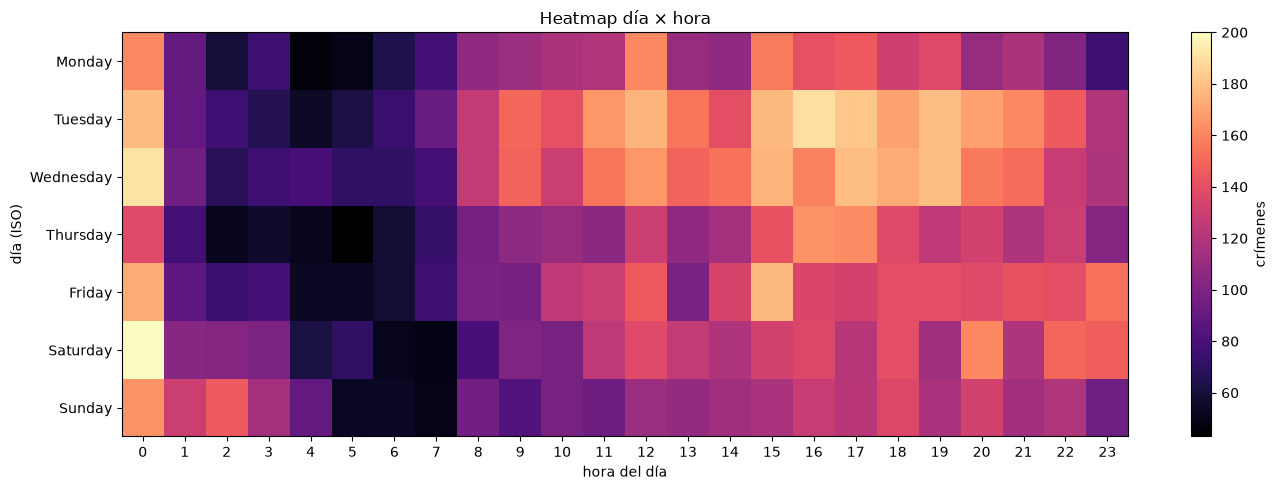

In [13]:
dh = q("SELECT day_of_week, day_name, hour, crime_count FROM warehouse.vw_day_hour")
# pivot a matriz completa 7x24 (rellena celdas vacías con 0)
DIAS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
mat = dh.pivot_table(index="day_of_week", columns="hour",
                     values="crime_count", aggfunc="sum", fill_value=0)
mat = mat.reindex(index=range(1, 8), columns=range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(mat.values, aspect="auto", cmap="magma")
ax.set_xticks(range(24)); ax.set_yticks(range(7)); ax.set_yticklabels(DIAS)
ax.set_xlabel("hora del día"); ax.set_ylabel("día (ISO)")
ax.set_title("Heatmap día × hora")
fig.colorbar(im, ax=ax, label="crímenes")
plt.tight_layout()


In [14]:
mat

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
day_of_week,,,,,,,,,,,,,,,,,,,,,,,,
1,161,90,59,75,46,50,64,77,107,112,118,120,161,110,107,157,141,145,131,138,110,118,102,75
2,178,90,76,66,55,63,74,92,127,150,141,166,176,155,140,177,190,181,169,179,169,161,146,120
3,191,95,68,75,79,70,71,78,127,149,130,155,166,149,154,176,159,179,173,179,156,152,128,119
4,138,77,52,56,52,43,58,73,97,106,110,105,130,107,115,142,164,162,138,125,132,119,130,103
5,173,88,74,78,54,53,58,75,99,97,125,129,145,99,134,177,135,133,140,140,138,142,140,154
6,200,104,103,100,62,70,51,49,79,101,98,124,138,127,119,132,136,122,140,113,161,119,150,147
7,165,130,146,115,90,53,54,50,96,83,98,94,112,109,113,117,128,123,136,117,132,114,120,95


## 7 · Conclusiones (completar tras ver los outputs)

- ¿Qué día concentra más crimen? ¿Hay pico de fin de semana?
- ¿A qué horas se acumula? (típicamente tarde-noche)
- Con la ventana actual, ¿la tendencia mensual dice algo o hay que ampliar
  los datos primero?
- ¿El heatmap día×hora confirma la firma esperada para un dashboard?
